# Analysis 1: How fast does a video reach the trending list?

**Business question.** After upload, how quickly does a video reach the trending list, and does that depend on category or country? A channel team can use this to judge when a video has missed its window.

**Data.** Every video-country pair that first trended after 2020-08-12 (videos already trending on the first day of the data are left out because their real first day is unknown). The data contains only videos that did trend, so this measures how fast successful videos got there, not the chance of trending.

**Metric.** Days from the upload date to the first trending day, both as UTC dates. The main outcome is whether a video trended by the next day (0 or 1 days).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

from streampulse.analysis import load_time_to_trend, odds_ratios
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, apply_chart_style
from streampulse.database import connect

apply_chart_style()
with connect() as connection:
    time_to_trend = load_time_to_trend(connection)

time_to_trend.groupby("country").size().loc[COUNTRIES].rename("videos")

country
IN    78676
US    46942
GB    47407
Name: videos, dtype: int64

In [2]:
def share_with_ci(outcomes):
    successes, total = outcomes.sum(), outcomes.size
    ci_low, ci_high = proportion_confint(successes, total, method="wilson")
    return pd.Series({"videos": total, "pct": 100 * successes / total, "ci_low": 100 * ci_low, "ci_high": 100 * ci_high})


def epsilon_squared(kruskal_h, n_observations, n_groups):
    # Effect size for Kruskal-Wallis: roughly the share of rank variance explained by the groups.
    return (kruskal_h - n_groups + 1) / (n_observations - n_groups)

## 1. Countries differ a lot

Share of videos that trended by the next day, with 95% Wilson confidence intervals, and a Kruskal-Wallis test on days to trend across the three countries. With this many videos almost any difference is statistically significant, so the effect size (epsilon squared) matters more than the p-value.

In [3]:
country_summary = (
    time_to_trend.groupby("country")["trended_by_next_day"].apply(share_with_ci).unstack()
    .join(time_to_trend.groupby("country")["days_to_trend"].median().rename("median_days"))
    .loc[COUNTRIES].round(1)
)

kruskal_h, kruskal_p = stats.kruskal(*[group["days_to_trend"] for _, group in time_to_trend.groupby("country")])
print(f"Kruskal-Wallis across countries: H = {kruskal_h:,.0f}, p = {kruskal_p:.1g}, "
      f"epsilon squared = {epsilon_squared(kruskal_h, len(time_to_trend), 3):.3f}")
country_summary

Kruskal-Wallis across countries: H = 20,259, p = 0, epsilon squared = 0.117


,videos,pct,ci_low,ci_high,median_days
country,,,,,
IN,78676.0,87.3,87.1,87.5,1.0
US,46942.0,57.4,56.9,57.8,1.0
GB,47407.0,57.2,56.8,57.7,1.0


## 2. Category matters much less than country

Same outcome by category within each country, for categories with at least 200 videos in that country.

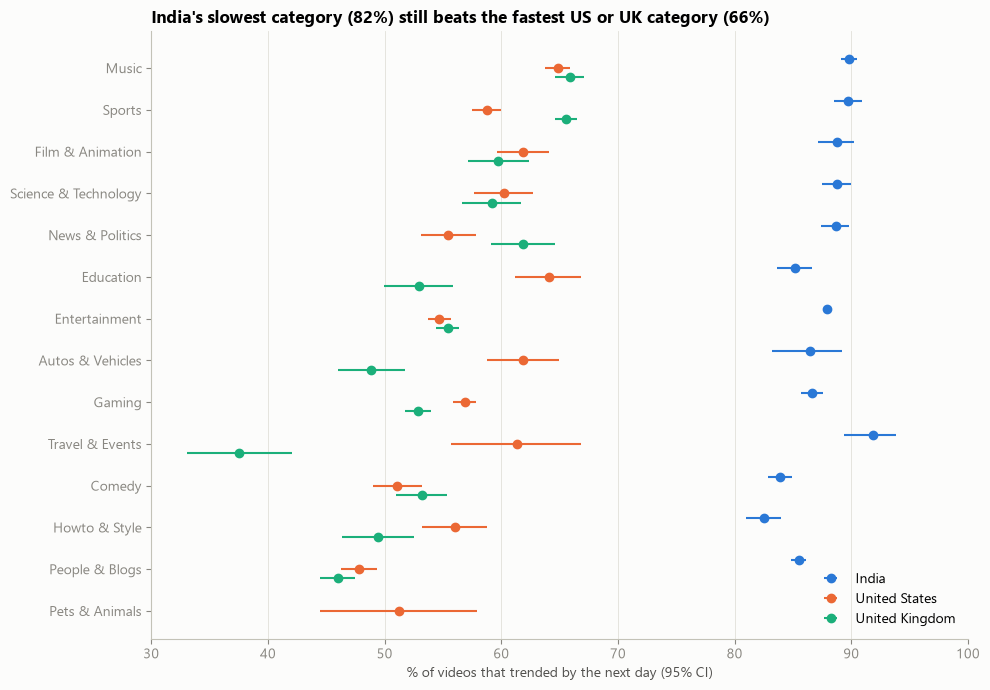

IN: 13 categories, by-next-day share ranges 82.5% to 91.9%, Kruskal-Wallis p = 5e-184, epsilon squared = 0.011
US: 14 categories, by-next-day share ranges 47.8% to 64.8%, Kruskal-Wallis p = 6e-87, epsilon squared = 0.009
GB: 13 categories, by-next-day share ranges 37.5% to 65.9%, Kruskal-Wallis p = 7e-210, epsilon squared = 0.021


In [4]:
category_summary = (
    time_to_trend.groupby(["country", "category"])["trended_by_next_day"].apply(share_with_ci).unstack()
    .query("videos >= 200")
    .reset_index()
)
category_order = (
    category_summary.groupby("category")["pct"].mean().sort_values().index
)

fig, ax = plt.subplots(figsize=(10, 7))
for offset, country in zip([0.22, 0, -0.22], COUNTRIES):
    country_rows = category_summary[category_summary["country"] == country].set_index("category").reindex(category_order)
    y_positions = np.arange(len(category_order)) + offset
    ax.errorbar(country_rows["pct"], y_positions,
                xerr=[country_rows["pct"] - country_rows["ci_low"], country_rows["ci_high"] - country_rows["pct"]],
                fmt="o", markersize=6, color=COUNTRY_COLORS[country], ecolor=COUNTRY_COLORS[country],
                elinewidth=1.5, label=COUNTRY_NAMES[country])
ax.set_yticks(range(len(category_order)), category_order)
ax.set_xlabel("% of videos that trended by the next day (95% CI)")
ax.set_xlim(30, 100)
ax.grid(axis="y", visible=False)
ax.set_title("India's slowest category (82%) still beats the fastest US or UK category (66%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

for country in COUNTRIES:
    country_videos = time_to_trend[time_to_trend["country"] == country]
    large_categories = country_videos.groupby("category").filter(lambda rows: len(rows) >= 200)
    groups = [rows["days_to_trend"] for _, rows in large_categories.groupby("category")]
    h_statistic, p_value = stats.kruskal(*groups)
    country_range = category_summary.loc[category_summary["country"] == country, "pct"]
    print(f"{country}: {len(groups)} categories, by-next-day share ranges {country_range.min():.1f}% to "
          f"{country_range.max():.1f}%, Kruskal-Wallis p = {p_value:.1g}, "
          f"epsilon squared = {epsilon_squared(h_statistic, len(large_categories), len(groups)):.3f}")

## 3. Part of the country gap is upload timing

The trending list is captured once a day, at a time the dataset does not record. A video can appear on the list dated the same day as its upload only if it was uploaded before that day's capture. 99% of same-day trenders were uploaded before 11:00 UTC (before 07:53 UTC in India, 09:01 in the US, 10:47 in the UK), so the capture happens in the UTC morning, and the shaded band below is a rough estimate of it.

So the later in the UTC day a video is uploaded, the less time it has before the next capture, and the less likely it is to count as trending by the next day. The three countries upload at very different UTC hours: India's uploads cluster in the Indian morning and afternoon, which is early UTC, while US and UK uploads cluster in their afternoons, which is late UTC.

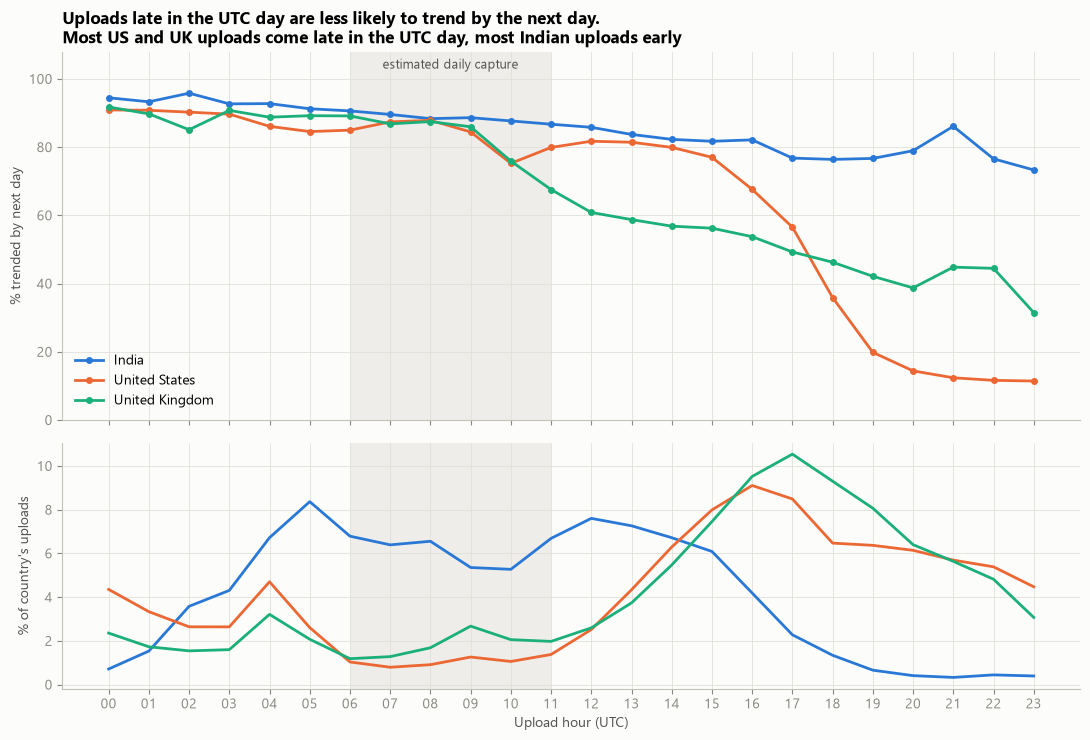

upload_hour_utc,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
country,,,,,,,,,,,,,,,,,,,,,
IN,94.5,93.3,95.8,92.7,92.8,91.3,90.6,89.6,88.3,88.6,...,82.3,81.7,82.1,76.8,76.4,76.7,78.9,86.1,76.6,73.3
US,90.9,90.8,90.2,89.7,86.1,84.6,85.0,87.4,87.9,84.5,...,79.9,77.0,67.6,56.5,35.9,19.8,14.4,12.4,11.6,11.4
GB,91.8,89.8,85.1,90.8,88.8,89.2,89.1,86.8,87.5,86.0,...,56.8,56.2,53.7,49.3,46.3,42.1,38.7,44.8,44.5,31.5


In [5]:
hourly = (
    time_to_trend.groupby(["upload_hour_utc", "country"])["trended_by_next_day"]
    .agg(videos="size", pct=lambda outcomes: 100 * outcomes.mean())
    .reset_index()
)
hourly["pct_of_country_uploads"] = 100 * hourly["videos"] / hourly.groupby("country")["videos"].transform("sum")

fig, (share_ax, volume_ax) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, height_ratios=[3, 2])
for country in COUNTRIES:
    country_hours = hourly[hourly["country"] == country]
    share_ax.plot(country_hours["upload_hour_utc"], country_hours["pct"], marker="o", markersize=4,
                  color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
    volume_ax.plot(country_hours["upload_hour_utc"], country_hours["pct_of_country_uploads"],
                   color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
for ax in (share_ax, volume_ax):
    ax.axvspan(6, 11, color="#e1e0d9", alpha=0.5, linewidth=0)
share_ax.text(8.5, 103, "estimated daily capture", ha="center", fontsize=9, color="#52514e")
share_ax.set_ylim(0, 108)
share_ax.set_ylabel("% trended by next day")
share_ax.set_title("Uploads late in the UTC day are less likely to trend by the next day.\n"
                   "Most US and UK uploads come late in the UTC day, most Indian uploads early")
share_ax.legend(loc="lower left")
volume_ax.set_ylabel("% of country's uploads")
volume_ax.set_xlabel("Upload hour (UTC)")
volume_ax.set_xticks(range(24), [f"{hour:02d}" for hour in range(24)])
plt.tight_layout()
plt.show()

hourly.pivot(index="upload_hour_utc", columns="country", values="pct")[COUNTRIES].round(1).T

## 4. How much of India's lead survives after controlling for upload hour and category

Logistic regression of trended-by-next-day on country, adding category and then upload hour (UTC) as controls. The US is the reference country. Only categories with at least 100 videos in every country are included, so all three countries are compared on the same categories.

In [6]:
shared_categories = time_to_trend.groupby("category").filter(
    lambda rows: rows["country"].nunique() == 3 and rows.groupby("country").size().min() >= 100
)
model_formulas = {
    "country only": "trended_by_next_day ~ C(country, Treatment('US'))",
    "+ category": "trended_by_next_day ~ C(country, Treatment('US')) + C(category)",
    "+ category + upload hour": "trended_by_next_day ~ C(country, Treatment('US')) + C(category) + C(upload_hour_utc)",
}

model_results = []
for model_name, formula in model_formulas.items():
    fitted_model = smf.logit(formula, data=shared_categories).fit(disp=0)
    country_odds = odds_ratios(fitted_model, "C(country")
    country_odds.index = country_odds.index.str.extract(r"T\.(\w+)\]", expand=False) + " vs US"
    model_results.append(country_odds.assign(model=model_name, pseudo_r2=fitted_model.prsquared))

print(f"{shared_categories['category'].nunique()} categories, {len(shared_categories):,} videos")
pd.concat(model_results).reset_index(names="comparison").set_index(["model", "comparison"]).round(3)

13 categories, 172,529 videos


odds_ratio  ci_low  ci_high  p_value  \
model                    comparison                                         
country only             GB vs US         0.995   0.970    1.021    0.719   
                         IN vs US         5.110   4.969    5.254    0.000   
+ category               GB vs US         0.988   0.962    1.014    0.348   
                         IN vs US         5.547   5.386    5.712    0.000   
+ category + upload hour GB vs US         1.064   1.034    1.096    0.000   
                         IN vs US         2.684   2.593    2.778    0.000   

                                     pseudo_r2  
model                    comparison             
country only             GB vs US        0.095  
                         IN vs US        0.095  
+ category               GB vs US        0.101  
                         IN vs US        0.101  
+ category + upload hour GB vs US        0.206  
                         IN vs US        0.206

## Finding

**Indian videos reach the list faster, and the lead is real but about half as large as it first looks.**

- 87.3% of Indian trending videos reached the list by the day after upload, against 57.4% in the US and 57.2% in the UK. Country explains far more of the variation (epsilon squared 0.117) than category does within a country (0.009 to 0.021).
- India is ahead in every category: its slowest category (Howto & Style, 82.5%) beats the fastest US or UK category (UK Music, 65.9%).
- Upload timing explains part of the gap. Controlling for upload hour and category, India's odds of trending by the next day fall from 5.5 times the US's to 2.7 times (95% CI 2.6 to 2.8). The UK and US stay about equal (1.06). For uploads between 00:00 and 09:00 UTC, all three countries are within 11 points of each other; the gap opens for uploads later in the UTC day.
- Across all three countries, about 95% of videos that trended did so within two days of upload. If a video is going to trend at all, it almost always happens fast.

**Limitations**

- The data only contains videos that trended. This describes how fast successful videos got there, not what makes a video trend.
- Days are counted between UTC calendar dates, and the daily capture time is unknown and varies, so time to trend cannot be measured in hours.
- The upload-hour control removes the capture-timing effect, but it would also absorb any real time-of-day effect.
- Categories are chosen by the uploader and are broad (Entertainment covers 43% of India's list).